Ce notebook presente un modele de Deep learning pour la variable cible 'TousAge_allergie_urgences'

In [2]:
import pandas as pd
import numpy as np

Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

C:\Users\gauxm\AppData\Local\Temp\ipykernel_31616\2492055701.py:4: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [3]:
#Suppression colonnes
Merge_final_FS_MLA = Merge_final.drop(columns=[
    '0an_bronchiolite_urgences', 
    '65plus_allergie_urgences',
    '0_14_allergie_urgences',
    '15_64_allergie_urgences',
    '0_14_asthme_urgences',
    '15_64_asthme_urgences',
    'TousAge_asthme_urgences',
    '65plus_asthme_urgences',
    '0an_bronchiolite_hospitalisation',
    'TousAge_allergie_hospitalisation',
    '65plus_allergie_hospitalisation',
    '0_14_allergie_hospitalisation',
    '15_64_allergie_hospitalisation',
    '0_14_asthme_hospitalisation',
    '15_64_asthme_hospitalisation',
    'TousAge_asthme_hospitalisation',
    '65plus_asthme_hospitalisation',
    'Ntop_Maladie_Respi_Chronique_tsage_9',
    'Npop_Maladie_Respi_Chronique_tsage_9',
    'Ntop_Maladie_Respi_Chronique_0-14_9',
    'Ntop_Maladie_Respi_Chronique_15-64_9',
    'Ntop_Maladie_Respi_Chronique_65+_9',
    'Npop_Maladie_Respi_Chronique_0-14_9',
    'Npop_Maladie_Respi_Chronique_15-64_9',
    'Npop_Maladie_Respi_Chronique_65+_9',
    'nom_dep',])

Merge_final_FS_MLA.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [4]:
#Met dans le bon type les variables

Merge_final_FS_MLA["code_dept"] = Merge_final_FS_MLA["code_dept"].astype("str")

Merge_final_FS_MLA['sos_present'] = Merge_final_FS_MLA['sos_present'].astype(int)

Merge_final_FS_MLA.info()

Merge_final_FS_MLA.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0


Étape 1 : Préparation du DataFrame & Découpage Temporel

In [5]:
# Copie de travail depuis Merge_final_FS_MLA
df = Merge_final_FS_MLA.copy()

# Extraction de l'année
df['annee'] = (
    df['date_semaine'].astype(str).str[:4].astype(int)
)

# Split temporel strict
df_train = df[df['annee'] <= 2022]
df_val = df[df['annee'] == 2023]
df_test = df[df['annee'] == 2024]

df.info()

df_test.info()

df_test.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 56 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee
156,2024-S01,01,0.667750,0.650833,0.086167,2.0555,0.003767,14.357143,42.928571,8.000000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
157,2024-S02,01,0.509437,0.638333,0.061333,1.7920,0.002724,16.242857,22.714286,30.785714,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
158,2024-S03,01,0.741125,1.568333,0.096500,1.8685,0.004689,16.784615,34.928571,16.727273,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
159,2024-S04,01,0.557813,1.220000,0.074167,1.9375,0.003691,21.714286,29.071429,15.250000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
160,2024-S05,01,0.704500,1.590000,0.141833,2.6190,0.004768,18.478571,35.500000,19.142857,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024


Étape 2 : Feature Engineering (Inertie & Saisons)

In [6]:
# Extraction du numéro de semaine
semaines = df['date_semaine'].astype(str).str.split('S').str[1].astype(float)

# Encodage cyclique (sinus / cosinus)
df['semaine_sin'] = np.sin(2 * np.pi * semaines / 52)
df['semaine_cos'] = np.cos(2 * np.pi * semaines / 52)

# Tri indispensable par département et ordre chronologique
df = df.sort_values(['code_dept', 'date_semaine'])

# Cible : la semaine future que l'on souhaite prédire (t+1)
df['target_futur'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(-1)

# Features basées strictement sur le passé (t-1 et t-2)
# La semaine juste avant (t-1)
df['lag_1_semaine_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(1)

# Il y a 2 semaines (t-2)
df['lag_2_semaines_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(2)

# Moyenne des 2 semaines d'avant
df['moyenne_passe_2w'] = (df['lag_1_semaine_avant'] + df['TousAge_allergie_urgences']) / 2 

# Nettoyage global de toutes les variables de lag et de la cible pour éviter les NaN
df = df.dropna(subset=['lag_1_semaine_avant', 'lag_2_semaines_avant', 'target_futur'])

# Mise à jour des splits Train / Val / Test avec les nouvelles features
df_train = df[df['annee'] <= 2022].copy()
df_val = df[df['annee'] == 2023].copy()
df_test = df[df['annee'] == 2024].copy()

# Vérification rapide
print(f'Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}')

Train : (9792, 62) | Val : (4992, 62) | Test : (4896, 62)


Étape 3 : Preprocessing pour Deep learning

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Colonnes à exclure des features (X)
cols_to_drop = ['TousAge_allergie_urgences', 'date_semaine', 'annee', 'target_futur']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

# Séparation X / y pour chaque split
X_train = df_train.drop(columns=cols_to_drop)
y_train = df_train['target_futur']

X_val = df_val.drop(columns=cols_to_drop)
y_val = df_val['target_futur']

X_test = df_test.drop(columns=cols_to_drop)
y_test = df_test['target_futur']

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f'Colonnes numériques ({len(num_cols)}) : {num_cols}')
print(f'Colonnes catégorielles ({len(cat_cols)}) : {cat_cols}')

# Construction du préprocesseur pour le KNN
preprocessor_dnn = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ]
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_dnn = preprocessor_dnn.fit_transform(X_train)
X_val_dnn = preprocessor_dnn.transform(X_val)
X_test_dnn = preprocessor_dnn.transform(X_test)

print('\nDimensions après preprocessing KNN :')
print(f'X_train_svr : {X_train_dnn.shape}')
print(f'X_val_svr   : {X_val_dnn.shape}')
print(f'X_test_svr  : {X_test_dnn.shape}')

Colonnes numériques (57) : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_genera

Étape 5 : Entraînement du Modèle et Validation Finale sur Test (2024)

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Récupération automatique du nombre de variables en entrée (153 colonnes)
input_dim = X_train_dnn.shape[1]

# Construction du modèle DNN  régression
model = Sequential([
    # Première couche cachée
    Dense(256, activation='relu', input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.4),
    
    # Seconde couche cachée
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    
    # Troisième couche pour condenser l'information
    Dense(64, activation='relu'),
    Dropout(0.2),
    
    # Couche de sortie continue
    Dense(1, activation='linear')
])

# Compilation du modèle avec les métriques MAE, RMSE et l'erreur MSE comme Loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error', # Fonction de coût pour la régression
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
    ]
)

model.summary()

# Callback d'arrêt précoce basé sur l'amélioration de la RMSE de validation
early_stopping = EarlyStopping(
    monitor='val_rmse',
    mode='min', # On cherche à minimiser l'erreur
    patience=12,
    restore_best_weights=True
)

# Entraînement du modèle
history = model.fit(
    X_train_dnn, y_train,
    validation_data=(X_val_dnn, y_val),
    epochs=60,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

c:\Users\gauxm\Documents\Projet_patho\venvpatho\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        39,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,177 (321.00 KB)

 Trainable params: 81,409 (318.00 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/60
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 584032.2500 - mae: 698.5543 - rmse: 764.2200 - val_loss: 384618.3750 - val_mae: 556.8344 - val_rmse: 620.1761
Epoch 2/60
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 199522.4688 - mae: 358.3426 - rmse: 446.6794 - val_loss: 105160.6953 - val_mae: 246.2781 - val_rmse: 324.2849
Epoch 3/60
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 103615.0781 - mae: 243.1034 - rmse: 321.8930 - val_loss: 92502.2188 - val_mae: 228.3232 - val_rmse: 304.1418
Epoch 4/60
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 90216.1641 - mae: 228.0612 - rmse: 300.3600 - val_loss: 82468.3516 - val_mae: 213.8322 - val_rmse: 287.1730
Epoch 5/60
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 81555.5781 - mae: 215.1770 - rmse: 285.5794 - val_loss: 68336.2891 - val_mae: 193.7772 - val_rmse: 261.4121
Epoch 6/60
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 74147.5781 - mae: 203.5858 - rmse: 272.3005 - val_loss: 61391.3594 - val_mae: 182.0450 - val_rm

In [9]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Génération des prédictions sur les différents jeux
y_pred_train = model.predict(X_train_dnn).flatten()
y_pred_val = model.predict(X_val_dnn).flatten()
y_pred_test = model.predict(X_test_dnn).flatten()

# Fonction pour afficher les scores
def evaluate_regression(y_true, y_pred, dataset_name):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    print(f"--- Performances DNN sur le jeu de {dataset_name} ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : {mae:.4f}")
    print(f"RMSE     : {rmse:.4f}\n")

# Évaluation
evaluate_regression(y_train, y_pred_train, "Train")
evaluate_regression(y_val, y_pred_val, "Validation")
evaluate_regression(y_test, y_pred_test, "Test Final")

306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 552us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 579us/step
--- Performances DNN sur le jeu de Train ---
R² Score : 0.5009
MAE      : 164.5766
RMSE     : 227.7492

--- Performances DNN sur le jeu de Validation ---
R² Score : 0.4452
MAE      : 175.1994
RMSE     : 240.9403

--- Performances DNN sur le jeu de Test Final ---
R² Score : 0.4103
MAE      : 164.4098
RMSE     : 225.6732



Visualisation de la courbe d'apprentissage (Loss / RMSE)


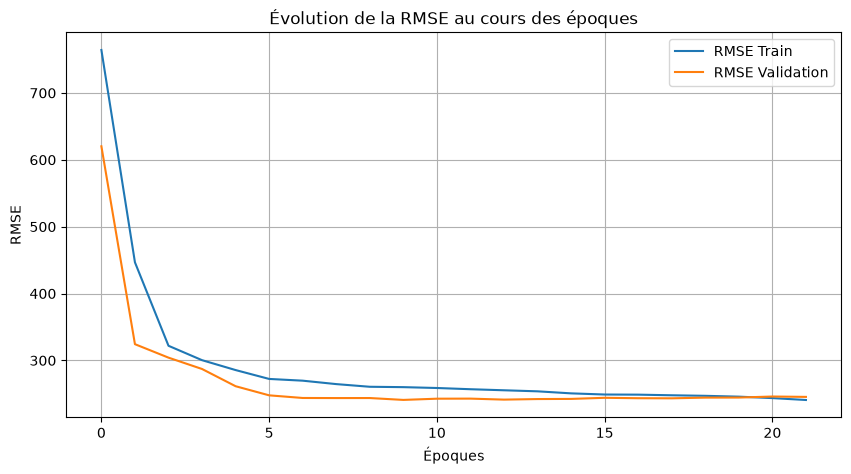

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history['rmse'], label='RMSE Train')
plt.plot(history.history['val_rmse'], label='RMSE Validation')
plt.title("Évolution de la RMSE au cours des époques")
plt.xlabel("Époques")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)
plt.show()

Analyse des résidus (Erreurs de prédiction)

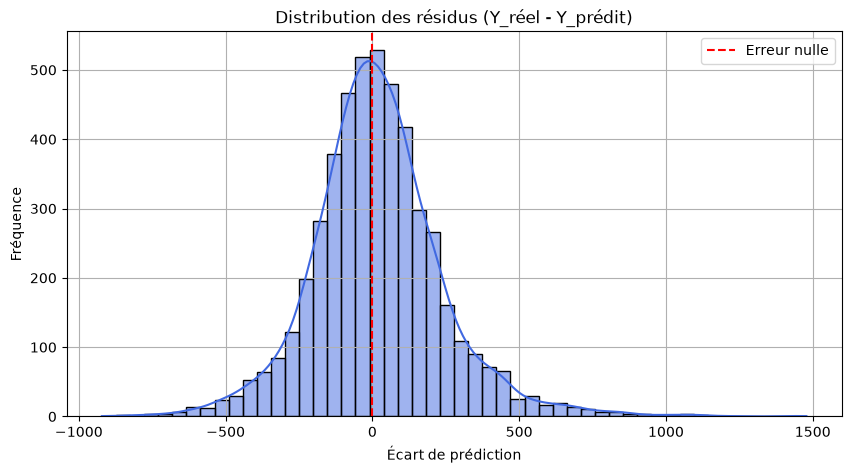

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul des résidus sur le jeu de test
residuals = y_test - y_pred_test

plt.figure(figsize=(10, 5))
sns.histplot(residuals, kde=True, bins=50, color='royalblue')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Erreur nulle')
plt.title("Distribution des résidus (Y_réel - Y_prédit)")
plt.xlabel("Écart de prédiction")
plt.ylabel("Fréquence")
plt.legend()
plt.grid(True)
plt.show()

Graphique de parité (Valeurs Réelles vs Prédites)

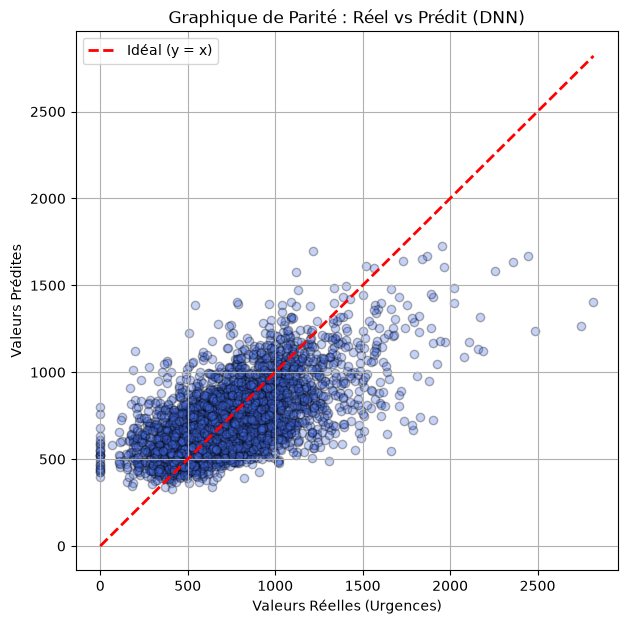

In [13]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_test, alpha=0.3, color='royalblue', edgecolor='k')

# Ligne idéale y = x (prédiction parfaite)
min_val = min(min(y_test), min(y_pred_test))
max_val = max(max(y_test), max(y_pred_test))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Idéal (y = x)')

plt.title("Graphique de Parité : Réel vs Prédit (DNN)")
plt.xlabel("Valeurs Réelles (Urgences)")
plt.ylabel("Valeurs Prédites")
plt.legend()
plt.grid(True)
plt.show()

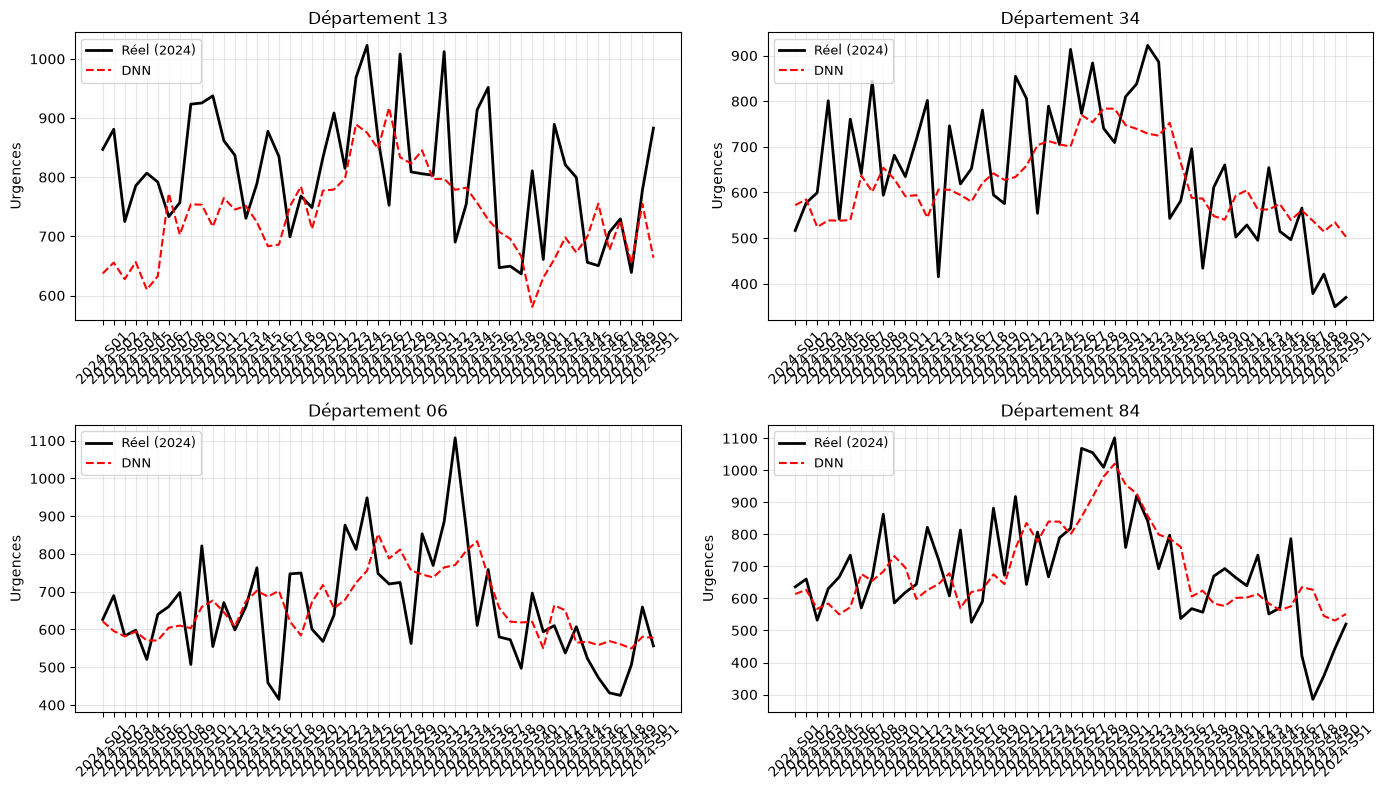

In [17]:
# Ajout des prédictions DNN dans une copie du DataFrame de test
df_test_viz = df_test.copy()
df_test_viz['pred_dnn'] = y_pred_test

# Sélection des départements d'intérêt
depts_cibles = ['13', '34', '06', '84']

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=False)
axes = axes.flatten()

for i, dept in enumerate(depts_cibles):
  ax = axes[i]
  sub_df = df_test_viz[df_test_viz['code_dept'] == dept]

  ax.plot(
      sub_df['date_semaine'],
      sub_df['target_futur'],
      label='Réel (2024)',
      color='black',
      linewidth=2,
  )
  ax.plot(
      sub_df['date_semaine'],
      sub_df['pred_dnn'],
      label='DNN',
      color='red',
      linestyle='--',
      linewidth=1.5,
  )

  ax.set_title(f'Département {dept}')
  ax.set_ylabel('Urgences')
  ax.legend(loc='upper left', fontsize=9)
  ax.grid(True, alpha=0.3)
  ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()